<a href="https://colab.research.google.com/github/Threebelt903744/tess-transit-hunter/blob/main/notebooks/01_single_star_bls.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##01 — Single-Star BLS Transit Detection

In [ ]:
pip install -q lightkurve

In [29]:
import os
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="lightkurve")

import numpy as np
import lightkurve as lk
import matplotlib.pyplot as plt

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)


def run_bls_transit_search(
    tic_id,
    planet_name,
    period_min=1.0,
    period_max=15.0,
    window_length=401,
    bin_size=0.015,
    xlim=0.3,
    sector_index=0,
    figsize=(10, 5)
):
    """Download a TESS SPOC light curve, clean/flatten it, run BLS, and plot the folded transit."""
    # 1. Search and download 2-minute cadence SPOC light curve
    search = lk.search_lightcurve(tic_id, mission="TESS", author="SPOC")
    lc = search[sector_index].download(download_dir=DATA_DIR)

    # 2. Clean and flatten (sigma_lower=20 preserves deep Hot Jupiter transits)
    clean_lc = (
        lc.remove_nans()
        .remove_outliers(sigma_upper=5, sigma_lower=20)
        .flatten(window_length=window_length)
    )

    # 3. Run Box Least Squares (BLS) periodogram
    period_grid = np.linspace(period_min, period_max, 10000)
    bls = clean_lc.to_periodogram(method="bls", period=period_grid, frequency_factor=500)

    best_period = float(bls.period_at_max_power.value)
    best_t0 = float(bls.transit_time_at_max_power.value)
    best_dur_hr = float(bls.duration_at_max_power.to("hour").value)
    best_depth_ppm = float(bls.depth_at_max_power.value * 1e6)

    print(f"=== {planet_name} ({tic_id}) ===")
    print(f"Period:   {best_period:.4f} d")
    print(f"t0:       {best_t0:.4f} BTJD")
    print(f"Duration: {best_dur_hr:.2f} hr")
    print(f"Depth:    {best_depth_ppm:.0f} ppm")

    # 4. Fold, bin, and plot (transit plot in darker grey and red)
    fig, ax = plt.subplots(figsize=figsize, facecolor='white')
    ax.set_facecolor('#f0f0f0')

    folded = clean_lc.fold(period=best_period, epoch_time=best_t0)
    folded.scatter(ax=ax, color='#555555', alpha=0.4, label="Unbinned (2-min cadence)")
    folded.bin(time_bin_size=bin_size).plot(ax=ax, color="red", lw=2.5, label="Binned")

    ax.set_xlim(-xlim, xlim)
    ax.set_title(f"{planet_name} ({tic_id}) — Phase-Folded TESS Transit", color='black', fontsize=12)
    ax.xaxis.label.set_color('black')
    ax.yaxis.label.set_color('black')
    ax.tick_params(colors='black')
    ax.grid(True, color='white', linestyle='-', linewidth=1.5)

    # Set tight layout and uniform subplots margins
    fig.subplots_adjust(left=0.1, right=0.95, top=0.9, bottom=0.15)
    plt.show()

    # Plot raw flux in darker grey with identical margins
    fig_raw, ax_raw = plt.subplots(figsize=figsize, facecolor='white')
    ax_raw.set_facecolor('#f0f0f0')

    lc.remove_nans().plot(ax=ax_raw, color='#555555', lw=0.8)

    ax_raw.set_title(f"{planet_name} ({tic_id}) — Raw TESS Flux", color='black', fontsize=12)
    ax_raw.xaxis.label.set_color('black')
    ax_raw.yaxis.label.set_color('black')
    ax_raw.tick_params(colors='black')
    ax_raw.grid(True, color='white', linestyle='-', linewidth=1.5)

    fig_raw.subplots_adjust(left=0.1, right=0.95, top=0.9, bottom=0.15)
    plt.show()

    return {
        "Planet": planet_name,
        "TIC ID": tic_id,
        "Period (d)": round(best_period, 4),
        "t0 (BTJD)": round(best_t0, 4),
        "Duration (hr)": round(best_dur_hr, 2),
        "Depth (ppm)": int(round(best_depth_ppm)),
    }

##Target 1: Pi Mensae c (TIC 261136679)

=== Pi Mensae c (TIC 261136679) ===
Period:   6.2701 d
t0:       1325.4970 BTJD
Duration: 2.40 hr
Depth:    187 ppm


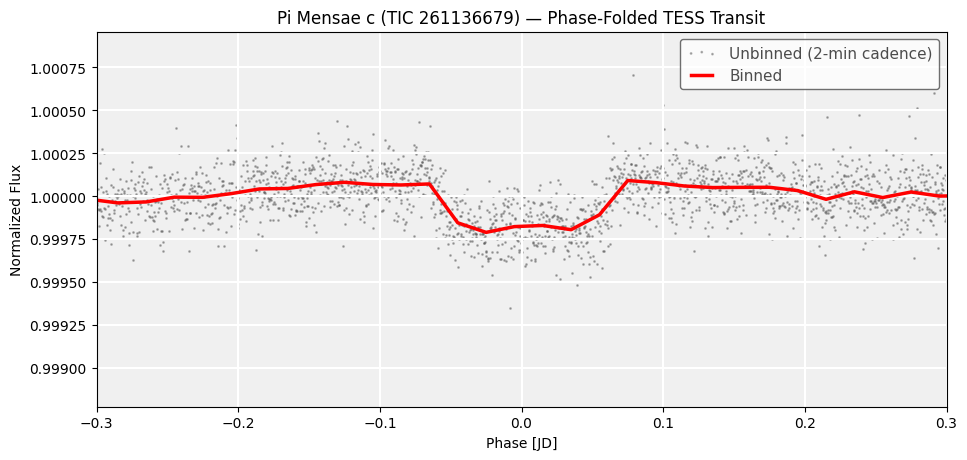

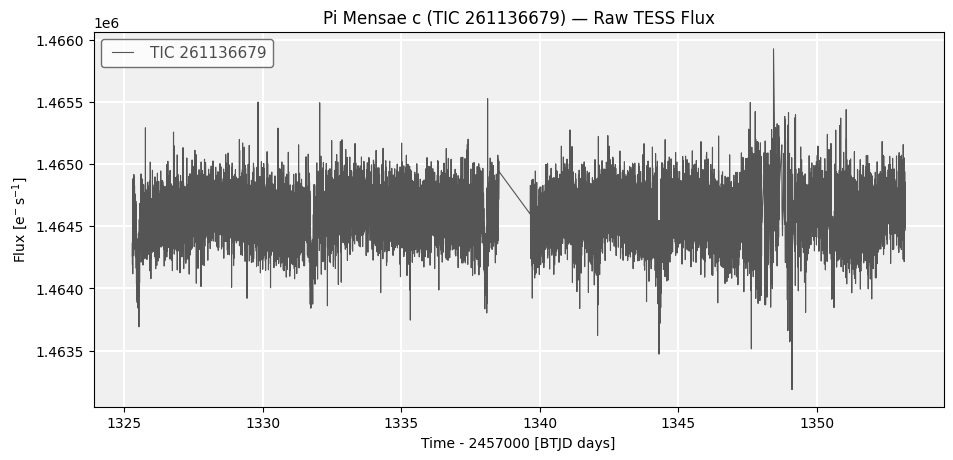

In [30]:
res_1 = run_bls_transit_search("TIC 261136679", "Pi Mensae c", bin_size=0.02, figsize=(10, 5))

##Target 2: Wasp-126 (TIC 25155310)

=== WASP-126 b (TIC 25155310) ===
Period:   3.2892 d
t0:       1327.5166 BTJD
Duration: 3.60 hr
Depth:    2275 ppm


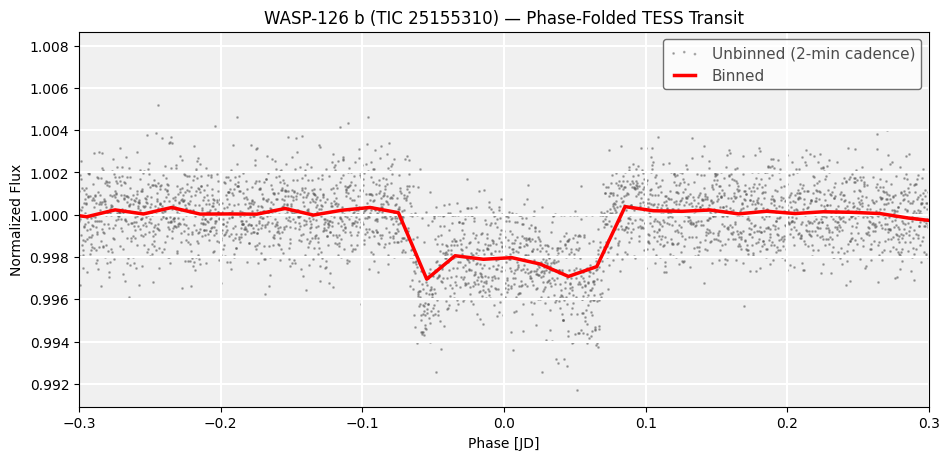

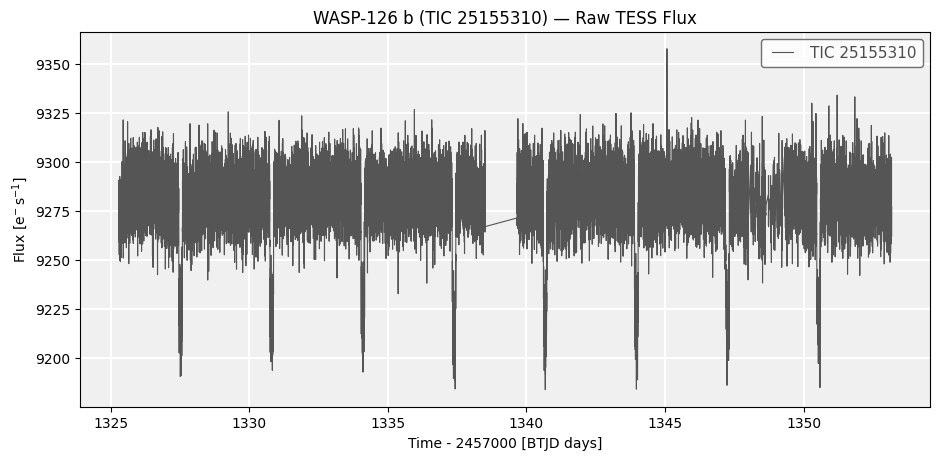

In [31]:
res_2 = run_bls_transit_search("TIC 25155310", "WASP-126 b", bin_size=0.02)

##Target 3: WASP-62 b (TIC 149603524)

=== WASP-62 b (TIC 149603524) ===
Period:   4.4107 d
t0:       1326.0806 BTJD
Duration: 3.60 hr
Depth:    11618 ppm


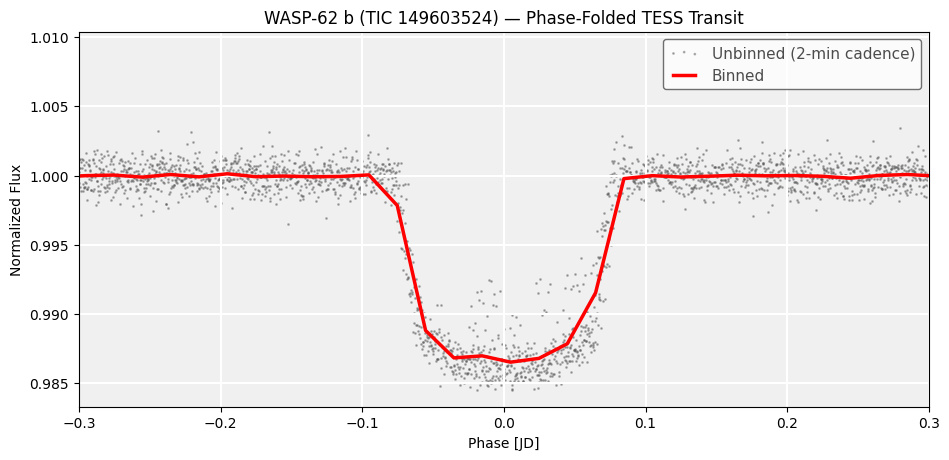

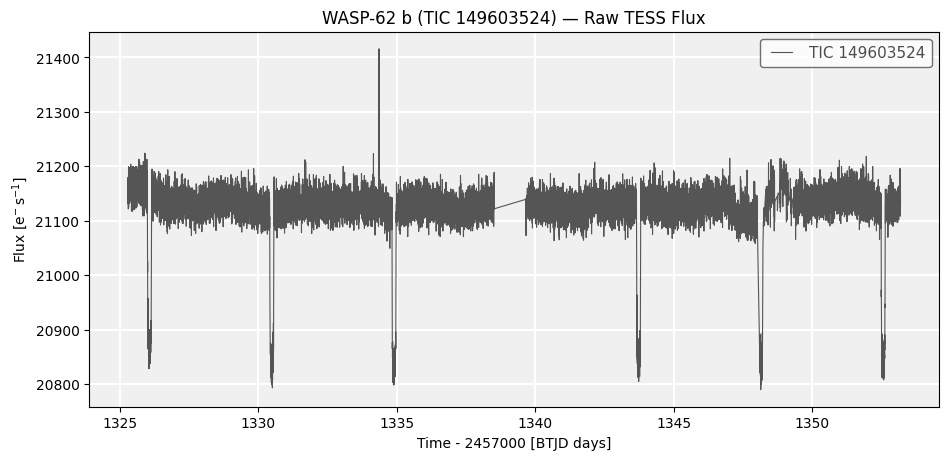

In [32]:
res_3 = run_bls_transit_search("TIC 149603524", "WASP-62 b", bin_size=0.02)

##Target 4: WASP-46 b (TIC 231663901)

=== WASP-46 b (TIC 231663901) ===
Period:   1.4298 d
t0:       1326.0153 BTJD
Duration: 1.20 hr
Depth:    10335 ppm


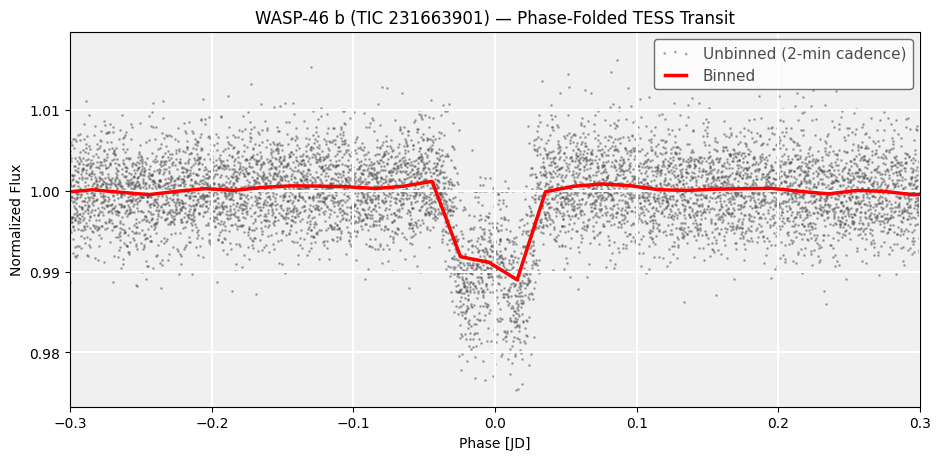

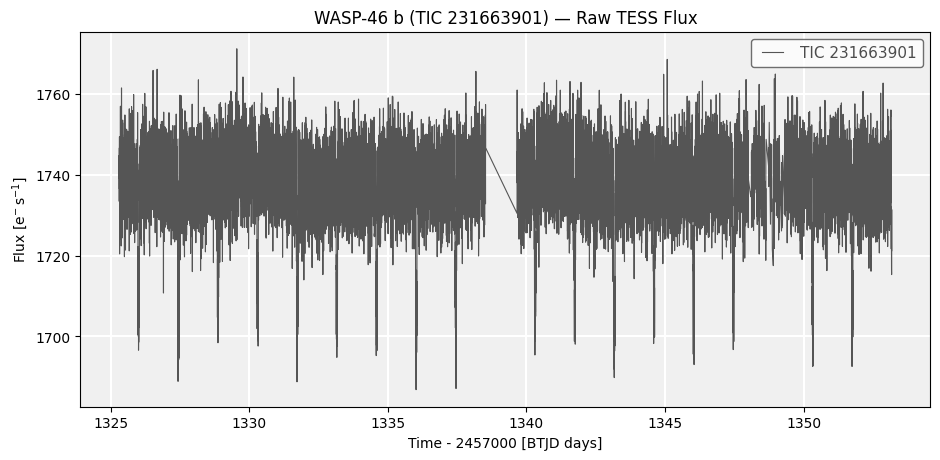

In [33]:
res_4 = run_bls_transit_search("TIC 231663901", "WASP-46 b", bin_size=0.02)

##Target 5: L 98-59 c (TIC 307210830)

=== L 98-59 c (TIC 307210830) ===
Period:   3.6911 d
t0:       1356.2024 BTJD
Duration: 1.20 hr
Depth:    1433 ppm


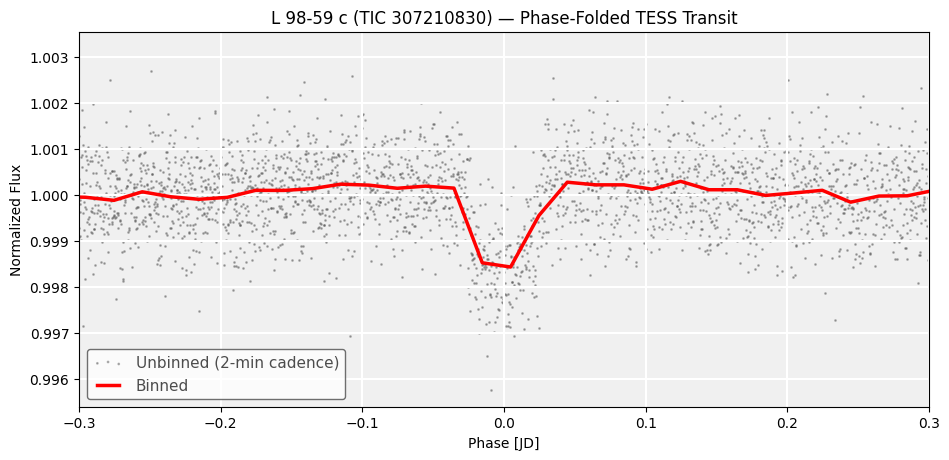

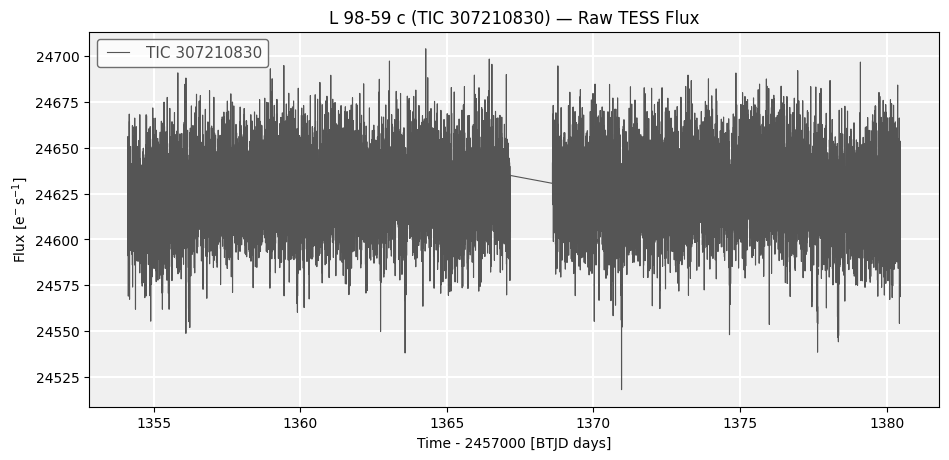

In [34]:
res_5 = run_bls_transit_search("TIC 307210830", "L 98-59 c", bin_size=0.02)